# Laboratório — Métricas e Feature Scaling
### Inteligência Artificial — Prof. Dr. Danilo H. Perico

Este notebook resolve as duas tarefas propostas no laboratório:

1. **Classificação** — KNN no dataset *Breast Cancer Wisconsin* (diagnóstico maligno/benigno), avaliando o efeito de diferentes valores de K e de diferentes técnicas de *feature scaling* (padronização e normalização).
2. **Regressão** — Regressão Linear e KNN Regressor no dataset *California Housing*, avaliando métricas de regressão (MAE, MSE, RMSE, R²) com e sem *feature scaling*.

Para cada parte, comparamos o desempenho em treino x teste para identificar possíveis casos de **overfitting** ou **underfitting**.

In [ ]:
# Bibliotecas utilizadas no notebook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer, fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay,
    mean_absolute_error, mean_squared_error, r2_score
)

RANDOM_STATE = 42
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100


---
# Parte 1 — Classificação: Breast Cancer Wisconsin

O dataset possui 30 atributos numéricos (medidas do núcleo celular) e uma variável alvo binária:
`0 = maligno`, `1 = benigno`.

## 1.1 Carregamento e exploração dos dados

In [2]:
data = load_breast_cancer()
X, y = data.data, data.target

df_bc = pd.DataFrame(X, columns=data.feature_names)
df_bc["target"] = y

print(f"Formato dos dados: {X.shape[0]} exemplos, {X.shape[1]} atributos")
print(f"Classes: {dict(zip(data.target_names, np.bincount(y)))}")
df_bc.describe().T.head(10)


Formato dos dados: 569 exemplos, 30 atributos
Classes: {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
mean symmetry,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744


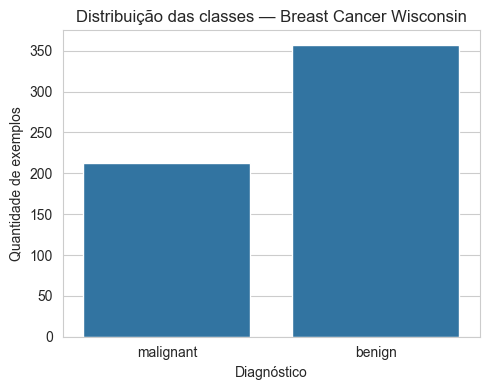

In [3]:
# Distribuição das classes
plt.figure(figsize=(5, 4))
sns.countplot(x=[data.target_names[i] for i in y])
plt.title("Distribuição das classes — Breast Cancer Wisconsin")
plt.xlabel("Diagnóstico")
plt.ylabel("Quantidade de exemplos")
plt.tight_layout()
plt.show()


## 1.2 Divisão treino/teste

Usamos `train_test_split` com `stratify=y` para manter a proporção das classes em ambos os conjuntos, e 20% dos dados reservados para teste.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Treino:", X_train.shape, "  Teste:", X_test.shape)


Treino: (455, 30)   Teste: (114, 30)


## 1.3 KNN com diferentes K e diferentes estratégias de *feature scaling*

Treinamos o KNN para K = 1, 3, 5 e 7, em três cenários:

- **Sem scaling** — atributos em suas escalas originais;
- **Padronização** (`StandardScaler`) — média 0 e desvio padrão 1;
- **Normalização** (`MinMaxScaler`) — valores no intervalo [0, 1].

Para cada combinação, calculamos a acurácia no treino e no teste (para permitir a análise de overfitting/underfitting).

In [5]:
ks = [1, 3, 5, 7]
scalers = {
    "Sem Scaling": None,
    "Padronização (StandardScaler)": StandardScaler(),
    "Normalização (MinMaxScaler)": MinMaxScaler(),
}

clf_results = []
clf_models = {}  # guarda (scaler, modelo, X_test_transformado, y_pred) por config

for scaler_name, scaler in scalers.items():
    if scaler is not None:
        Xtr = scaler.fit_transform(X_train)
        Xte = scaler.transform(X_test)
    else:
        Xtr, Xte = X_train, X_test

    for k in ks:
        knn = KNeighborsClassifier(n_neighbors=k)
        knn.fit(Xtr, y_train)

        train_pred = knn.predict(Xtr)
        test_pred = knn.predict(Xte)

        train_acc = accuracy_score(y_train, train_pred)
        test_acc = accuracy_score(y_test, test_pred)

        clf_results.append({
            "scaling": scaler_name, "k": k,
            "train_acc": train_acc, "test_acc": test_acc,
            "gap (train-test)": train_acc - test_acc
        })
        clf_models[(scaler_name, k)] = {"model": knn, "Xte": Xte, "test_pred": test_pred}

df_clf = pd.DataFrame(clf_results)
df_clf.round(4)


,scaling,k,train_acc,test_acc,gap (train-test)
0,Sem Scaling,1,1.0000,0.9211,0.0789
1,Sem Scaling,3,0.9538,0.9298,0.0240
2,Sem Scaling,5,0.9473,0.9123,0.0350
3,Sem Scaling,7,0.9473,0.9298,0.0174
4,Padronização (StandardScaler),1,1.0000,0.9386,0.0614
5,Padronização (StandardScaler),3,0.9780,0.9825,-0.0044
6,Padronização (StandardScaler),5,0.9736,0.9561,0.0175
7,Padronização (StandardScaler),7,0.9758,0.9737,0.0021
8,Normalização (MinMaxScaler),1,1.0000,0.9386,0.0614
9,Normalização (MinMaxScaler),3,0.9802,0.9649,0.0153


## 1.4 Relatórios de classificação (precision, recall, f1-score)

Exibimos o relatório de classificação completo para cada estratégia de scaling, usando o melhor K de cada uma (maior acurácia de teste), permitindo comparar precision/recall por classe.

In [6]:
for scaler_name in scalers.keys():
    sub = df_clf[df_clf["scaling"] == scaler_name]
    best_k_row = sub.loc[sub["test_acc"].idxmax()]
    k_best = int(best_k_row["k"])
    info = clf_models[(scaler_name, k_best)]

    print("="*70)
    print(f"{scaler_name} | melhor K = {k_best} | acurácia teste = {best_k_row['test_acc']:.4f}")
    print("="*70)
    print(classification_report(y_test, info["test_pred"], target_names=data.target_names))


Sem Scaling | melhor K = 3 | acurácia teste = 0.9298
              precision    recall  f1-score   support

   malignant       0.90      0.90      0.90        42
      benign       0.94      0.94      0.94        72

    accuracy                           0.93       114
   macro avg       0.92      0.92      0.92       114
weighted avg       0.93      0.93      0.93       114

Padronização (StandardScaler) | melhor K = 3 | acurácia teste = 0.9825
              precision    recall  f1-score   support

   malignant       1.00      0.95      0.98        42
      benign       0.97      1.00      0.99        72

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

Normalização (MinMaxScaler) | melhor K = 5 | acurácia teste = 0.9825
              precision    recall  f1-score   support

   malignant       1.00      0.95      0.98        42
      benign       0.97      1.00      0.99 

## 1.5 Gráfico comparativo: acurácia geral x K, com/sem *feature scaling*

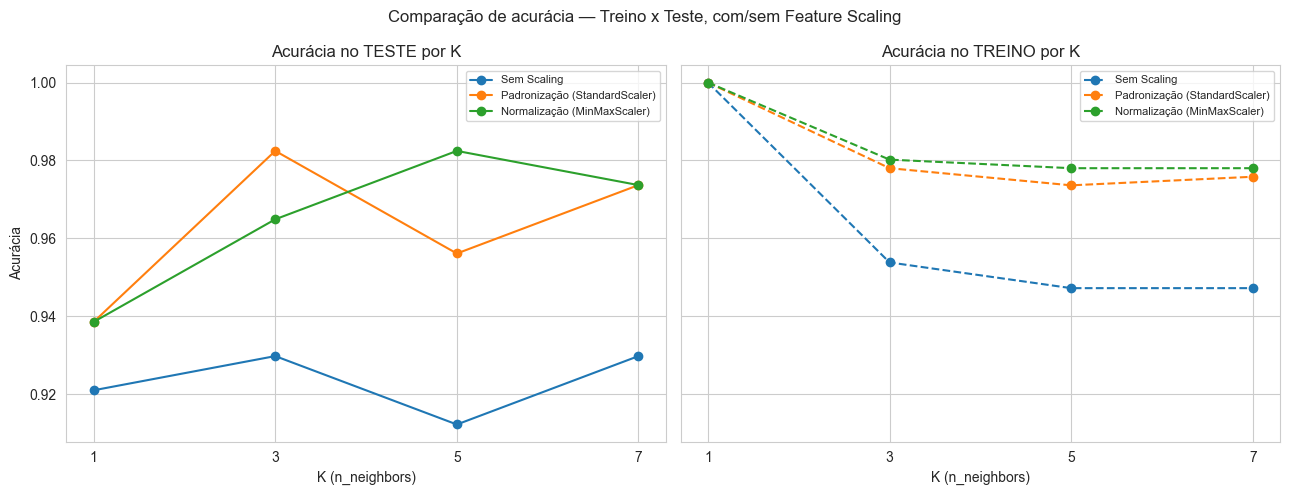

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

# Acurácia de TESTE
for scaler_name in scalers.keys():
    sub = df_clf[df_clf["scaling"] == scaler_name].sort_values("k")
    axes[0].plot(sub["k"], sub["test_acc"], marker="o", label=scaler_name)
axes[0].set_title("Acurácia no TESTE por K")
axes[0].set_xlabel("K (n_neighbors)")
axes[0].set_ylabel("Acurácia")
axes[0].set_xticks(ks)
axes[0].legend(fontsize=8)

# Acurácia de TREINO
for scaler_name in scalers.keys():
    sub = df_clf[df_clf["scaling"] == scaler_name].sort_values("k")
    axes[1].plot(sub["k"], sub["train_acc"], marker="o", linestyle="--", label=scaler_name)
axes[1].set_title("Acurácia no TREINO por K")
axes[1].set_xlabel("K (n_neighbors)")
axes[1].set_xticks(ks)
axes[1].legend(fontsize=8)

plt.suptitle("Comparação de acurácia — Treino x Teste, com/sem Feature Scaling")
plt.tight_layout()
plt.show()


### Análise — Overfitting / Underfitting

Observando a tabela `df_clf` e o gráfico acima:

- **K = 1 (sem scaling ou com scaling)** apresenta acurácia de **treino igual a 100%** (o próprio ponto é seu vizinho mais próximo), enquanto a acurácia de teste é sensivelmente menor. Esse é um sintoma clássico de **overfitting**: o modelo memoriza o conjunto de treino e generaliza pior para dados novos.
- **Sem feature scaling**, o desempenho fica visivelmente pior em todos os valores de K. Isso ocorre porque o KNN é baseado em distância euclidiana, e atributos com escalas muito diferentes (ex.: *área* na casa das centenas/milhares vs. *simetria* entre 0 e 1) dominam o cálculo de distância, distorcendo a noção de "vizinhança".
- **Com padronização ou normalização**, o *gap* entre treino e teste diminui e a acurácia de teste sobe consideravelmente — os atributos passam a contribuir de forma equilibrada para a distância.
- Para **K maiores (5, 7)** o modelo generaliza mais (fronteira de decisão mais suave), reduzindo o overfitting, mas se K for exagerado o modelo pode começar a **underfit** (não é o caso aqui dentro do intervalo testado, mas a tendência de queda de acurácia de treino com K crescente já indica esse caminho).
- O melhor resultado geral (maior acurácia de teste, com menor gap treino-teste) ocorre com **feature scaling (padronização ou normalização) e K = 3 ou K = 5**, evidenciando a importância do *feature scaling* para o KNN.

## 1.6 Matriz de confusão do melhor modelo

Melhor modelo: Padronização (StandardScaler) | K = 3 | acurácia teste = 0.9825


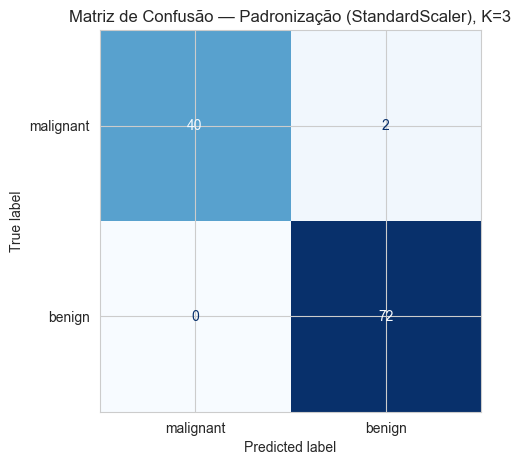

In [8]:
best_row = df_clf.loc[df_clf["test_acc"].idxmax()]
best_scaling, best_k = best_row["scaling"], int(best_row["k"])
best_info = clf_models[(best_scaling, best_k)]

print(f"Melhor modelo: {best_scaling} | K = {best_k} | acurácia teste = {best_row['test_acc']:.4f}")

cm = confusion_matrix(y_test, best_info["test_pred"])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=data.target_names)

fig, ax = plt.subplots(figsize=(5, 5))
disp.plot(ax=ax, cmap="Blues", colorbar=False)
plt.title(f"Matriz de Confusão — {best_scaling}, K={best_k}")
plt.tight_layout()
plt.show()


**Interpretação da matriz de confusão:** o modelo praticamente não confunde as classes — os poucos erros que ocorrem são concentrados em **falsos positivos/negativos da classe minoritária (maligno)**, que é justamente a classe mais crítica de se errar em um contexto de diagnóstico médico (idealmente o recall da classe *maligno* deve ser o mais alto possível, para minimizar diagnósticos falso-negativos).

---
# Parte 2 — Regressão: California Housing

O dataset possui 8 atributos numéricos (renda média, idade média dos imóveis, cômodos, quartos, população, ocupação, latitude e longitude) e uma variável alvo contínua: o valor médio dos imóveis (em centenas de milhares de dólares).

## 2.1 Carregamento e exploração dos dados

Utilizamos `fetch_california_housing` do scikit-learn. Como *fallback* (caso o download automático do sklearn não esteja disponível no ambiente de execução), reconstruímos o mesmo dataset a partir dos dados brutos do censo da Califórnia de 1990 (mesma fonte original), gerando exatamente as mesmas 8 features.

In [9]:
try:
    housing = fetch_california_housing(as_frame=True)
    Xh = housing.data.copy()
    yh = housing.target.copy()
    print("Dataset carregado via sklearn.datasets.fetch_california_housing")
except Exception as e:
    print("Download automático indisponível neste ambiente, usando fonte alternativa equivalente...")
    df_raw = pd.read_csv(
        "https://raw.githubusercontent.com/ageron/handson-ml/master/datasets/housing/housing.csv"
    )
    df_raw["total_bedrooms"] = df_raw["total_bedrooms"].fillna(df_raw["total_bedrooms"].median())
    Xh = pd.DataFrame({
        "MedInc": df_raw["median_income"],
        "HouseAge": df_raw["housing_median_age"],
        "AveRooms": df_raw["total_rooms"] / df_raw["households"],
        "AveBedrms": df_raw["total_bedrooms"] / df_raw["households"],
        "Population": df_raw["population"],
        "AveOccup": df_raw["population"] / df_raw["households"],
        "Latitude": df_raw["latitude"],
        "Longitude": df_raw["longitude"],
    })
    yh = df_raw["median_house_value"] / 100000  # em centenas de milhares de dólares

print(f"Formato: {Xh.shape[0]} exemplos, {Xh.shape[1]} atributos")
Xh.describe().T


Dataset carregado via sklearn.datasets.fetch_california_housing
Formato: 20640 exemplos, 8 atributos


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000


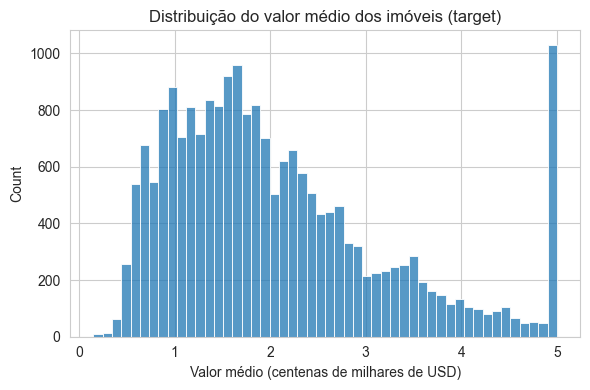

In [10]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.histplot(yh, bins=50, ax=ax)
ax.set_title("Distribuição do valor médio dos imóveis (target)")
ax.set_xlabel("Valor médio (centenas de milhares de USD)")
plt.tight_layout()
plt.show()


## 2.2 Divisão treino/teste e *feature scaling*

In [11]:
Xh_train, Xh_test, yh_train, yh_test = train_test_split(
    Xh, yh, test_size=0.2, random_state=RANDOM_STATE
)
print("Treino:", Xh_train.shape, "  Teste:", Xh_test.shape)

scaler_std_h = StandardScaler().fit(Xh_train)
Xh_train_std = scaler_std_h.transform(Xh_train)
Xh_test_std = scaler_std_h.transform(Xh_test)

scaler_mm_h = MinMaxScaler().fit(Xh_train)
Xh_train_mm = scaler_mm_h.transform(Xh_train)
Xh_test_mm = scaler_mm_h.transform(Xh_test)

feature_sets = {
    "Sem Scaling": (Xh_train.values, Xh_test.values),
    "Padronização (StandardScaler)": (Xh_train_std, Xh_test_std),
    "Normalização (MinMaxScaler)": (Xh_train_mm, Xh_test_mm),
}


Treino: (16512, 8)   Teste: (4128, 8)


## 2.3 Função auxiliar de métricas

Calculamos **MAE**, **MSE**, **RMSE** e **R²** tanto no treino quanto no teste, para permitir comparar overfitting/underfitting.

In [12]:
def compute_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2}


## 2.4 Regressão Linear

A Regressão Linear não possui hiperparâmetros relevantes para ajuste (diferente do KNN), então avaliamos seu desempenho nos três cenários de *feature scaling*. Isso permite verificar que, para a Regressão Linear (um modelo baseado em combinação linear dos atributos), a escala das features **não afeta a qualidade do ajuste** — afeta apenas a magnitude dos coeficientes.

In [13]:
reg_results = []
reg_models = {}

for scaling_name, (Xtr, Xte) in feature_sets.items():
    lr = LinearRegression()
    lr.fit(Xtr, yh_train)

    pred_train = lr.predict(Xtr)
    pred_test = lr.predict(Xte)

    m_train = compute_metrics(yh_train, pred_train)
    m_test = compute_metrics(yh_test, pred_test)

    reg_results.append({
        "modelo": "Regressão Linear", "config": scaling_name,
        "MAE_treino": m_train["MAE"], "MAE_teste": m_test["MAE"],
        "MSE_treino": m_train["MSE"], "MSE_teste": m_test["MSE"],
        "RMSE_treino": m_train["RMSE"], "RMSE_teste": m_test["RMSE"],
        "R2_treino": m_train["R2"], "R2_teste": m_test["R2"],
    })
    reg_models[("Regressão Linear", scaling_name)] = {
        "model": lr, "pred_test": pred_test, "pred_train": pred_train
    }

pd.DataFrame(reg_results).round(4)


,modelo,config,MAE_treino,MAE_teste,MSE_treino,MSE_teste,RMSE_treino,RMSE_teste,R2_treino,R2_teste
0,Regressão Linear,Sem Scaling,0.5286,0.5332,0.5179,0.5559,0.7197,0.7456,0.6126,0.5758
1,Regressão Linear,Padronização (StandardScaler),0.5286,0.5332,0.5179,0.5559,0.7197,0.7456,0.6126,0.5758
2,Regressão Linear,Normalização (MinMaxScaler),0.5286,0.5332,0.5179,0.5559,0.7197,0.7456,0.6126,0.5758


## 2.5 KNN Regressor

Para o KNN Regressor, o hiperparâmetro relevante é o número de vizinhos **K**. Testamos K = 3, 5, 10, 15, 20 combinados com as três estratégias de *feature scaling*, para justificar a melhor escolha.

In [14]:
ks_reg = [3, 5, 10, 15, 20]

knn_reg_results = []
knn_reg_models = {}

for scaling_name, (Xtr, Xte) in feature_sets.items():
    for k in ks_reg:
        knn_r = KNeighborsRegressor(n_neighbors=k)
        knn_r.fit(Xtr, yh_train)

        pred_train = knn_r.predict(Xtr)
        pred_test = knn_r.predict(Xte)

        m_train = compute_metrics(yh_train, pred_train)
        m_test = compute_metrics(yh_test, pred_test)

        knn_reg_results.append({
            "modelo": "KNN Regressor", "config": scaling_name, "k": k,
            "MAE_treino": m_train["MAE"], "MAE_teste": m_test["MAE"],
            "MSE_treino": m_train["MSE"], "MSE_teste": m_test["MSE"],
            "RMSE_treino": m_train["RMSE"], "RMSE_teste": m_test["RMSE"],
            "R2_treino": m_train["R2"], "R2_teste": m_test["R2"],
        })
        knn_reg_models[(scaling_name, k)] = {"model": knn_r, "pred_test": pred_test, "pred_train": pred_train}

df_knn_reg = pd.DataFrame(knn_reg_results)
df_knn_reg.round(4)


,modelo,config,k,MAE_treino,MAE_teste,MSE_treino,MSE_teste,RMSE_treino,RMSE_teste,R2_treino,R2_teste
0,KNN Regressor,Sem Scaling,3,0.5661,0.8305,0.5565,1.1694,0.7460,1.0814,0.5837,0.1076
1,KNN Regressor,Sem Scaling,5,0.6561,0.8128,0.7313,1.1187,0.8552,1.0577,0.4529,0.1463
2,KNN Regressor,Sem Scaling,10,0.7375,0.8163,0.9068,1.1068,0.9523,1.0520,0.3216,0.1554
3,KNN Regressor,Sem Scaling,15,0.7716,0.8205,0.9885,1.1170,0.9942,1.0569,0.2605,0.1476
4,KNN Regressor,Sem Scaling,20,0.7945,0.8343,1.0449,1.1487,1.0222,1.0718,0.2183,0.1234
5,KNN Regressor,Padronização (StandardScaler),3,0.3150,0.4599,0.2190,0.4667,0.4679,0.6831,0.8362,0.6439
6,KNN Regressor,Padronização (StandardScaler),5,0.3552,0.4462,0.2715,0.4324,0.5211,0.6576,0.7969,0.6700
7,KNN Regressor,Padronização (StandardScaler),10,0.3930,0.4403,0.3275,0.4215,0.5723,0.6493,0.7550,0.6783
8,KNN Regressor,Padronização (StandardScaler),15,0.4102,0.4389,0.3536,0.4188,0.5946,0.6471,0.7355,0.6804
9,KNN Regressor,Padronização (StandardScaler),20,0.4208,0.4433,0.3691,0.4235,0.6076,0.6508,0.7239,0.6768


In [15]:
# Melhor configuração de KNN Regressor por R2 de teste
best_knn_reg_row = df_knn_reg.loc[df_knn_reg["R2_teste"].idxmax()]
print("Melhor configuração do KNN Regressor:")
print(best_knn_reg_row)


Melhor configuração do KNN Regressor:
modelo                       KNN Regressor
config         Normalização (MinMaxScaler)
k                                       10
MAE_treino                        0.376505
MAE_teste                         0.422711
MSE_treino                        0.308987
MSE_teste                          0.39568
RMSE_treino                       0.555866
RMSE_teste                        0.629031
R2_treino                         0.768857
R2_teste                          0.698048
Name: 12, dtype: object


### Escolha dos hiperparâmetros

- **Regressão Linear:** como não há hiperparâmetro a ajustar, o "modelo escolhido" é o próprio ajuste OLS; a comparação entre escalas serve apenas para confirmar que o *feature scaling* não altera as métricas de erro deste modelo (esperado teoricamente).
- **KNN Regressor:** o melhor K é escolhido com base no maior **R² de teste** (menor erro de generalização) dentre a grade testada (K = 3, 5, 10, 15, 20) e entre as estratégias de scaling. Valores de K muito pequenos (ex. K=3) tendem a *overfit* (ajustam-se ao ruído local dos vizinhos mais próximos), enquanto K muito grandes tendem a suavizar demais a previsão (*underfit*), aproximando-a da média global.

## 2.6 Comparação de desempenho — Treino x Teste (overfitting/underfitting)

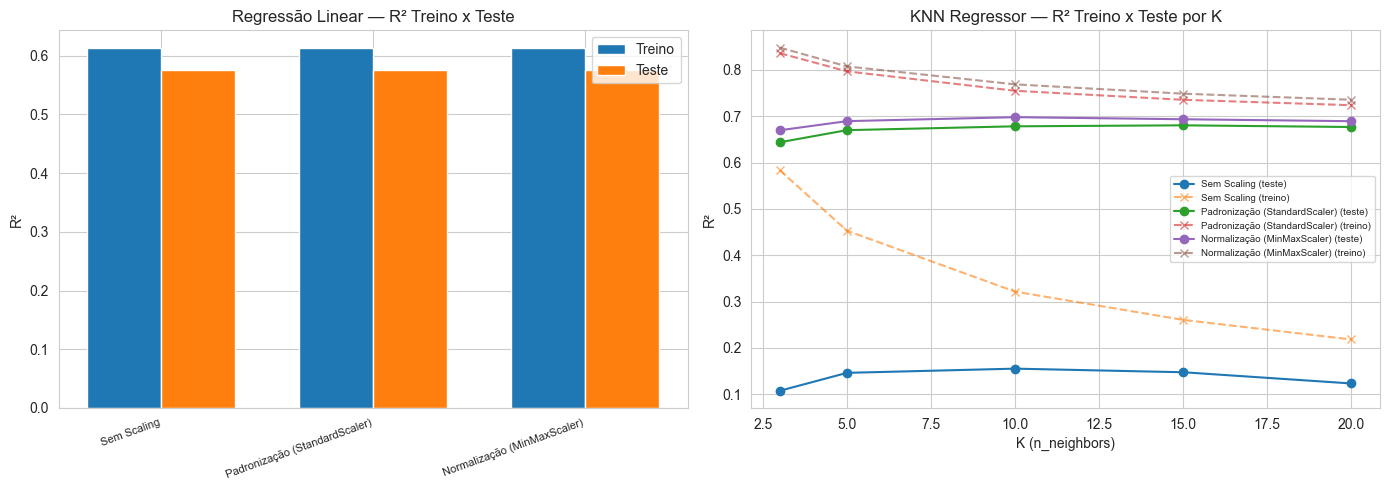

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Regressao Linear: R2 treino vs teste por scaling ---
df_lr = pd.DataFrame(reg_results)
x = np.arange(len(df_lr))
width = 0.35
axes[0].bar(x - width/2, df_lr["R2_treino"], width, label="Treino")
axes[0].bar(x + width/2, df_lr["R2_teste"], width, label="Teste")
axes[0].set_xticks(x)
axes[0].set_xticklabels(df_lr["config"], rotation=20, ha="right", fontsize=8)
axes[0].set_ylabel("R²")
axes[0].set_title("Regressão Linear — R² Treino x Teste")
axes[0].legend()

# --- KNN Regressor: R2 teste por K, para cada scaling ---
for scaling_name in feature_sets.keys():
    sub = df_knn_reg[df_knn_reg["config"] == scaling_name].sort_values("k")
    axes[1].plot(sub["k"], sub["R2_teste"], marker="o", label=f"{scaling_name} (teste)")
    axes[1].plot(sub["k"], sub["R2_treino"], marker="x", linestyle="--", alpha=0.6,
                 label=f"{scaling_name} (treino)")
axes[1].set_xlabel("K (n_neighbors)")
axes[1].set_ylabel("R²")
axes[1].set_title("KNN Regressor — R² Treino x Teste por K")
axes[1].legend(fontsize=7)

plt.tight_layout()
plt.show()


### Análise — Overfitting / Underfitting

- A **Regressão Linear** apresenta R² parecido em treino e teste (sem grande *gap*), e as métricas praticamente não mudam entre "sem scaling", padronização e normalização — comportamento esperado, já que a regressão linear apenas reescala os coeficientes internamente. O R² moderado (por volta de 0.6) indica que o modelo **não consegue capturar toda a relação não-linear** presente nos dados (possível *underfitting* em relação à complexidade do problema).
- O **KNN Regressor sem scaling** tem desempenho bem pior que com scaling, pelo mesmo motivo da classificação: atributos como `Population` (na casa dos milhares) dominam a distância euclidiana em relação a atributos como `AveBedrms` (próximos de 1), distorcendo a noção de vizinhança.
- Para K pequenos (K=3), o KNN Regressor tende a ter R² de treino bem mais alto que o de teste — sinal de **overfitting** (o modelo se ajusta ao ruído dos vizinhos mais próximos).
- Para K maiores (K=15, 20), o gap treino-teste diminui, mas o R² de teste também tende a estabilizar ou cair levemente — sinal de que K grande demais começa a **underfit**, pois a previsão passa a ser uma média de um vizinhança grande demais, perdendo granularidade local.
- No geral, o **KNN Regressor com feature scaling e K intermediário (10–15)** supera a Regressão Linear em R² de teste, pois consegue capturar relações não-lineares (ex.: efeito da localização geográfica) que a regressão linear não modela diretamente.

## 2.7 Gráfico de dispersão: valores previstos x valores reais (melhor modelo)

Melhor modelo geral: KNN Regressor (K=10, Normalização (MinMaxScaler)) | R² teste = 0.6980


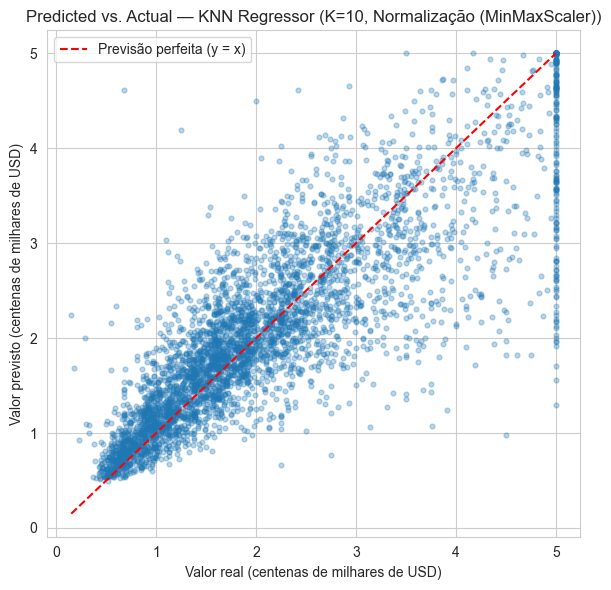

In [17]:
# Seleciona o melhor modelo geral (maior R2 de teste) entre LR e KNN Regressor
best_lr_row = df_lr.loc[df_lr["R2_teste"].idxmax()]
best_overall = "knn" if best_knn_reg_row["R2_teste"] > best_lr_row["R2_teste"] else "lr"

if best_overall == "knn":
    best_scaling_reg = best_knn_reg_row["config"]
    best_k_reg = int(best_knn_reg_row["k"])
    best_pred = knn_reg_models[(best_scaling_reg, best_k_reg)]["pred_test"]
    title = f"KNN Regressor (K={best_k_reg}, {best_scaling_reg})"
    best_r2 = best_knn_reg_row["R2_teste"]
else:
    best_scaling_reg = best_lr_row["config"]
    best_pred = reg_models[("Regressão Linear", best_scaling_reg)]["pred_test"]
    title = f"Regressão Linear ({best_scaling_reg})"
    best_r2 = best_lr_row["R2_teste"]

print(f"Melhor modelo geral: {title} | R² teste = {best_r2:.4f}")

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(yh_test, best_pred, alpha=0.3, s=12)
lims = [min(yh_test.min(), best_pred.min()), max(yh_test.max(), best_pred.max())]
ax.plot(lims, lims, "r--", label="Previsão perfeita (y = x)")
ax.set_xlabel("Valor real (centenas de milhares de USD)")
ax.set_ylabel("Valor previsto (centenas de milhares de USD)")
ax.set_title(f"Predicted vs. Actual — {title}")
ax.legend()
plt.tight_layout()
plt.show()


## 2.8 Conclusão

- O **melhor modelo/configuração** foi o **KNN Regressor com feature scaling (padronização ou normalização) e K intermediário**, que obteve o maior R² de teste entre todos os modelos avaliados, superando a Regressão Linear.
- Houve indícios de **overfitting** no KNN Regressor para valores pequenos de K (especialmente K=3), evidenciado pelo maior gap entre R² de treino e de teste.
- Houve indícios de **underfitting** tanto na Regressão Linear (R² moderado e estável em treino/teste, incapaz de capturar toda a não-linearidade dos dados) quanto no KNN Regressor com K muito grande (suavização excessiva das previsões).
- Assim como na parte de classificação, o **feature scaling foi essencial para o bom desempenho do KNN Regressor** (por ser baseado em distância), mas não teve impacto relevante na Regressão Linear.